#### Curva de habilidad del XGB frente al nº de PCs de presión (sin gradiente), y punto de oleaje
Objetivo: ver si con **solo PCs de presión** (que el PVAR simula bien) llegamos a la habilidad de las 30 PCs con gradiente (corr 6 h test ≈ 0.78), y en qué nº de componentes deja de mejorar.

- `PUNTO`: fichero de oleaje (el actual o el offshore). La PIT y la armónica se ajustan aquí, igual que en 00.
- `PCS_MSL`: CSV con muchas PCs de presión (p. ej. 100), horarias, de la PCA de 01 con más componentes.

In [5]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from utils.pit.piece_wise_marginal import PiecewiseMarginal, to_normal
from utils.pit.empirical_marginal import EmpiricalPiece
from utils.pit.gpd_marginal import GPDPiece
from utils.tv_var.harmonic_standardizer import HarmonicStandardizer

In [10]:
#### Entradas
PUNTOS = {"actual": "inputs/waves_bulk.csv",
          "offshore": "inputs/waves_bulk_p102.csv"}       # ← ruta del punto offshore
PCS_MSL = "outputs/pca/pcs_msl_100.csv"                     # ← PCs de presión con muchas componentes
PCS_REF = r"C:\Users\alonsoap\Documents\Proyectos\two_stage_model\_archivo\outputs\seleccion_6h\pcs_seleccionadas_6h.csv"   # 30 PCs actuales (msl + grad), referencia

train = slice("1985-01-01", "2015-12-31")
LAGS = [0, 6, 12, 18, 24, 30, 36]
PAR = dict(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)

In [11]:
def z_6h(fichero):
    """Hs → PIT (empírica + GPD > p95, ajustada en 1985–2015) → normal → armónica → media 6 h centrada, como en 00 y 04B."""
    w = pd.read_csv(fichero, index_col=0, parse_dates=True)["VHM0"].dropna()
    marg = PiecewiseMarginal([EmpiricalPiece(), GPDPiece()], [0.95]).fit(w.loc[train])
    z0 = to_normal(pd.Series(marg.cdf(w.values), index=w.index)).to_frame("VHM0")
    z = HarmonicStandardizer(n_harmonics=3).fit(z0.loc[train]).transform(z0)["VHM0"]
    z6 = z.rolling("6h", center=True).mean()
    return z6[z6.index.hour.isin([0, 6, 12, 18])].dropna()

def lagged(p):
    X = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in LAGS}, axis=1).reindex(p.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    return X.dropna()

def habilidad(pcs, z6):
    X = lagged(pcs); idx = X.index.intersection(z6.index); X, y = X.loc[idx], z6.loc[idx]
    tr = idx < "2016-01-01"
    m = XGBRegressor(**PAR).fit(X[tr], y[tr])
    f = pd.Series(m.predict(X[~tr]), index=X.index[~tr])
    d = lambda s: s.resample("D").mean()
    return {"corr 6h": f.corr(y[~tr]), "corr diaria": d(f).corr(d(y[~tr])), "R² 6h": 1 - (y[~tr] - f).var() / y[~tr].var()}, m, list(X.columns)

In [12]:
#### PCs 6-horarias
seis = lambda df: df[df.index.hour.isin([0, 6, 12, 18])]
pcs_msl = seis(pd.read_csv(PCS_MSL, index_col=0, parse_dates=True))
pcs_ref = pd.read_csv(PCS_REF, index_col=0, parse_dates=True)
print(pcs_msl.shape, pcs_ref.shape)

Z = {k: z_6h(f) for k, f in PUNTOS.items()}

(126864, 100) (126864, 30)


In [13]:
#### 1. Curva: habilidad frente al nº de PCs de presión, en cada punto (+ referencia de las 30 con gradiente)
N_LISTA = [5, 10, 13, 20, 30, 40, 50, 75, 100]
N_LISTA = [n for n in N_LISTA if n <= pcs_msl.shape[1]]
filas = []
for punto, z6 in Z.items():
    ref, _, _ = habilidad(pcs_ref, z6)
    filas.append({"punto": punto, "PCs": "30 ref (msl+grad)", **ref})
    for n in N_LISTA:
        met, _, _ = habilidad(pcs_msl.iloc[:, :n], z6)
        filas.append({"punto": punto, "PCs": n, **met})
        print(punto, n, {k: round(v, 3) for k, v in met.items()}, flush=True)
curva = pd.DataFrame(filas)
print(curva.round(3).to_string())

actual 5 {'corr 6h': np.float64(0.587), 'corr diaria': np.float64(0.614), 'R² 6h': 0.344}
actual 10 {'corr 6h': np.float64(0.696), 'corr diaria': np.float64(0.729), 'R² 6h': 0.484}
actual 13 {'corr 6h': np.float64(0.728), 'corr diaria': np.float64(0.762), 'R² 6h': 0.53}
actual 20 {'corr 6h': np.float64(0.747), 'corr diaria': np.float64(0.781), 'R² 6h': 0.556}
actual 30 {'corr 6h': np.float64(0.757), 'corr diaria': np.float64(0.79), 'R² 6h': 0.57}
actual 40 {'corr 6h': np.float64(0.768), 'corr diaria': np.float64(0.801), 'R² 6h': 0.587}
actual 50 {'corr 6h': np.float64(0.772), 'corr diaria': np.float64(0.806), 'R² 6h': 0.594}
actual 75 {'corr 6h': np.float64(0.773), 'corr diaria': np.float64(0.807), 'R² 6h': 0.595}
actual 100 {'corr 6h': np.float64(0.777), 'corr diaria': np.float64(0.812), 'R² 6h': 0.6}
offshore 5 {'corr 6h': np.float64(0.633), 'corr diaria': np.float64(0.662), 'R² 6h': 0.4}
offshore 10 {'corr 6h': np.float64(0.717), 'corr diaria': np.float64(0.75), 'R² 6h': 0.514}
offs

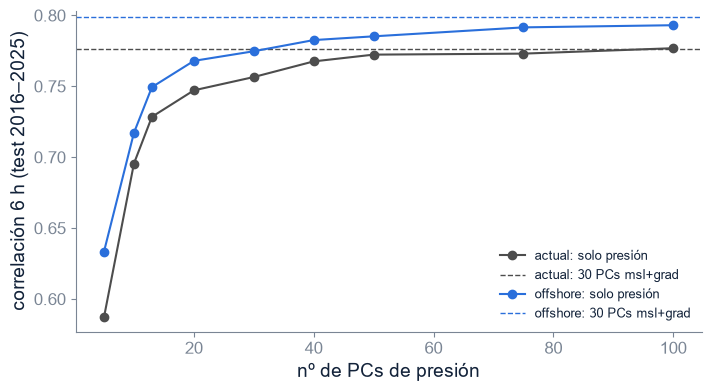

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
colores = {"actual": "0.3", "offshore": "#2a6fdb"}
for punto, d in curva.groupby("punto"):
    d_n = d[d["PCs"] != "30 ref (msl+grad)"]
    ax.plot(d_n["PCs"].astype(int), d_n["corr 6h"], "o-", color=colores.get(punto, "C0"), lw=1.5, label=f"{punto}: solo presión")
    ax.axhline(d.loc[d["PCs"] == "30 ref (msl+grad)", "corr 6h"].iloc[0], color=colores.get(punto, "C0"), ls="--", lw=1,
               label=f"{punto}: 30 PCs msl+grad")
ax.set(xlabel="nº de PCs de presión", ylabel="correlación 6 h (test 2016–2025)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.show()

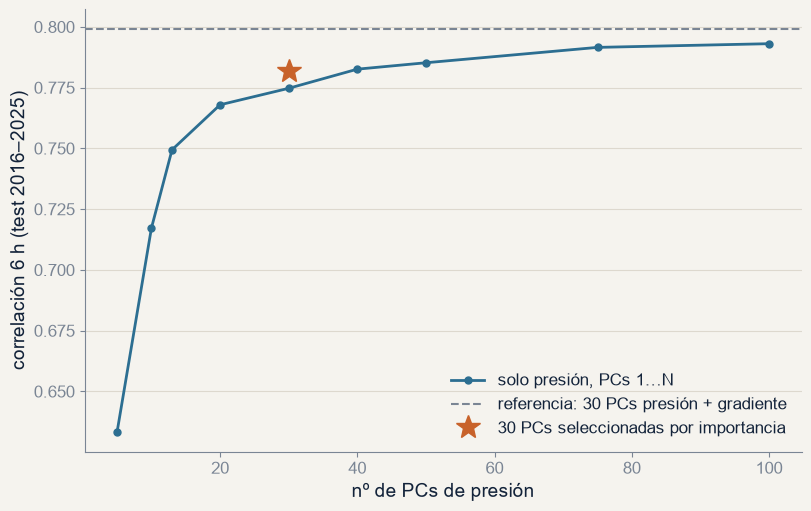

In [15]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

d = curva[curva["punto"] == "offshore"]
d_n = d[d["PCs"] != "30 ref (msl+grad)"].assign(n=lambda x: x["PCs"].astype(int)).sort_values("n")
ref = d.loc[d["PCs"] == "30 ref (msl+grad)", "corr 6h"].iloc[0]
r_sel = 0.782   # 30 PCs seleccionadas (02_PCA_selection)

fig, ax = plt.subplots(figsize=(8.0, 5.0), constrained_layout=True, facecolor=FONDO)
ax.plot(d_n["n"], d_n["corr 6h"], "o-", color=AZUL, lw=2, ms=5, label="solo presión, PCs 1…N")
ax.axhline(ref, color=GRIS, ls="--", lw=1.5, label="referencia: 30 PCs presión + gradiente")
ax.plot(30, r_sel, marker="*", ms=18, color=NARANJA, ls="none", zorder=5,
        label="30 PCs seleccionadas por importancia")

ax.set(xlabel="nº de PCs de presión", ylabel="correlación 6 h (test 2016–2025)")
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=12, loc="lower right")

fig.savefig("figuras/sens_npcs_curva.png", dpi=200, facecolor=FONDO)
plt.show()

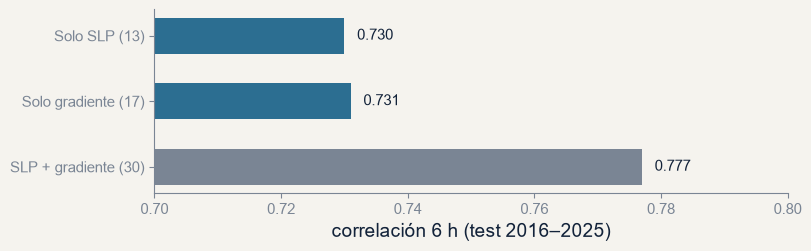

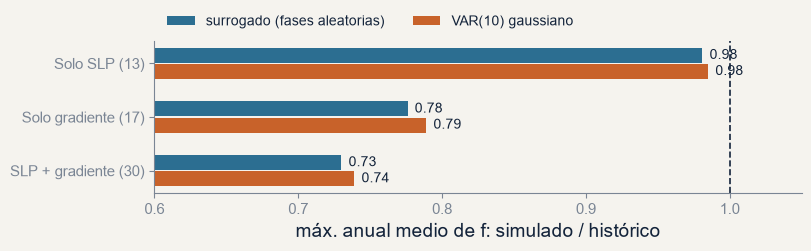

In [16]:
grupos = ["Solo SLP (13)", "Solo gradiente (17)", "SLP + gradiente (30)"]
corr   = [0.730, 0.731, 0.777]
r_surr = [0.981, 0.776, 0.730]
r_var  = [0.985, 0.789, 0.739]
y = np.arange(len(grupos))[::-1]

#### 1. Skill del XGB por grupo
fig, ax = plt.subplots(figsize=(8.0, 2.4), constrained_layout=True, facecolor=FONDO)
ax.barh(y, corr, height=0.55, color=[AZUL, AZUL, GRIS])
for yi, v in zip(y, corr):
    ax.text(v + 0.002, yi, f"{v:.3f}", va="center", fontsize=11)
ax.set_yticks(y, grupos)
ax.set(xlim=(0.70, 0.80), xlabel="correlación 6 h (test 2016–2025)")
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=11)
fig.savefig("figuras/sens_grupos_skill.png", dpi=200, facecolor=FONDO)
plt.show()

#### 2. Extremos de f: generador lineal / histórico
fig, ax = plt.subplots(figsize=(8.0, 2.4), constrained_layout=True, facecolor=FONDO)
ax.barh(y + 0.15, r_surr, height=0.28, color=AZUL, label="surrogado (fases aleatorias)")
ax.barh(y - 0.15, r_var, height=0.28, color=NARANJA, label="VAR(10) gaussiano")
ax.axvline(1, color=TINTA, lw=1.2, ls="--")
for yi, a, b in zip(y, r_surr, r_var):
    ax.text(a + 0.005, yi + 0.15, f"{a:.2f}", va="center", fontsize=10)
    ax.text(b + 0.005, yi - 0.15, f"{b:.2f}", va="center", fontsize=10)
ax.set_yticks(y, grupos)
ax.set(xlim=(0.6, 1.05), xlabel="máx. anual medio de f: simulado / histórico")
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=11)
ax.legend(frameon=False, fontsize=10, loc="lower left", ncol=2, bbox_to_anchor=(0, 1.0))
fig.savefig("figuras/sens_grupos_extremos.png", dpi=200, facecolor=FONDO)
plt.show()

In [ ]:
#### 2. Selección solo con presión: importancia del XGB con N_MAX PCs y eliminación hacia atrás
PUNTO_SEL = "offshore"                                      # ← el punto que vaya a usarse
N_MAX = 50                                                  # ← donde la curva se aplana
z6 = Z[PUNTO_SEL]
cols = list(pcs_msl.columns[:N_MAX])
met, m, nombres = habilidad(pcs_msl[cols], z6)
imp = pd.Series(m.feature_importances_, index=nombres)
imp_pc = imp.groupby(lambda s: s.rsplit("_l", 1)[0]).sum().sort_values()      # importancia por PC (sumando lags)

pasos = [{"nº PCs": len(cols), **met}]
listas = {len(cols): list(cols)}                                               # ← la lista de PCs de cada paso
while len(cols) > 5:
    cols = [c_ for c_ in cols if c_ != imp_pc.index[0]]                        # quita la menos importante
    imp_pc = imp_pc.drop(imp_pc.index[0])
    met, _, _ = habilidad(pcs_msl[cols], z6)
    pasos.append({"nº PCs": len(cols), **met})
    listas[len(cols)] = list(cols)
    if len(cols) % 5 == 0:
        print(len(cols), {k: round(v, 3) for k, v in met.items()}, flush=True)
seleccion = pd.DataFrame(pasos).set_index("nº PCs")
print(seleccion[["corr 6h", "corr diaria", "R² 6h"]].round(3).to_string())

45 {'corr 6h': np.float64(0.787), 'corr diaria': np.float64(0.818), 'R² 6h': 0.618}
40 {'corr 6h': np.float64(0.786), 'corr diaria': np.float64(0.818), 'R² 6h': 0.618}
35 {'corr 6h': np.float64(0.787), 'corr diaria': np.float64(0.818), 'R² 6h': 0.618}
30 {'corr 6h': np.float64(0.782), 'corr diaria': np.float64(0.814), 'R² 6h': 0.611}
25 {'corr 6h': np.float64(0.775), 'corr diaria': np.float64(0.807), 'R² 6h': 0.601}
20 {'corr 6h': np.float64(0.772), 'corr diaria': np.float64(0.804), 'R² 6h': 0.596}
15 {'corr 6h': np.float64(0.766), 'corr diaria': np.float64(0.798), 'R² 6h': 0.587}
10 {'corr 6h': np.float64(0.743), 'corr diaria': np.float64(0.773), 'R² 6h': 0.551}
5 {'corr 6h': np.float64(0.636), 'corr diaria': np.float64(0.666), 'R² 6h': 0.404}
        corr 6h  corr diaria  R² 6h
nº PCs                             
50        0.785        0.817  0.616
49        0.786        0.817  0.617
48        0.786        0.817  0.617
47        0.786        0.817  0.616
46        0.786        0.817 

In [ ]:
import json
N_SEL = 30                                                                     # ← el nº de PCs que te quedas
imp = pd.Series(m.feature_importances_, index=nombres)
imp_pc = imp.groupby(lambda s: s.rsplit("_l", 1)[0]).sum().sort_values(ascending=False)
sel = list(imp_pc.index[:N_SEL])
print(sel)
print(habilidad(pcs_msl[sel], z6)[0])                                          # debe dar ≈ 0.782

p = pd.read_csv(PCS_MSL, index_col=0, parse_dates=True)
p[p.index.hour.isin([0, 6, 12, 18])][sel].to_csv("outputs/pca/pcs_msl_sel_6h.csv", float_format="%.5f")
json.dump(sel, open("outputs/pca/pcs_msl_sel.json", "w"), indent=1)

['msl_PC4', 'msl_PC1', 'msl_PC3', 'msl_PC11', 'msl_PC6', 'msl_PC2', 'msl_PC34', 'msl_PC8', 'msl_PC27', 'msl_PC38', 'msl_PC17', 'msl_PC30', 'msl_PC13', 'msl_PC42', 'msl_PC36', 'msl_PC45', 'msl_PC12', 'msl_PC23', 'msl_PC43', 'msl_PC41', 'msl_PC32', 'msl_PC18', 'msl_PC35', 'msl_PC50', 'msl_PC7', 'msl_PC20', 'msl_PC21', 'msl_PC5', 'msl_PC24', 'msl_PC9']
{'corr 6h': np.float64(0.7821719044884418), 'corr diaria': np.float64(0.8135974624982888), 'R² 6h': 0.6114585522478642}


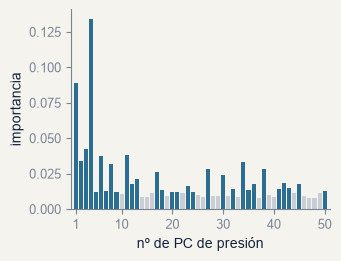

In [17]:
import json
sel = json.load(open("outputs/pca/pcs_msl_sel.json"))

#### Modelo con 50 PCs (el mismo del que sale la selección) → importancia por PC
cols50 = list(pcs_msl.columns[:50])
_, m50, nombres50 = habilidad(pcs_msl[cols50], Z["offshore"])
imp = pd.Series(m50.feature_importances_, index=nombres50)
imp_pc = imp.groupby(lambda s: s.rsplit("_l", 1)[0]).sum()
imp_pc.index = imp_pc.index.str.replace("msl_PC", "").astype(int)
imp_pc = imp_pc.sort_index()
n_sel = {int(s.replace("msl_PC", "")) for s in sel}

fig, ax = plt.subplots(figsize=(3.3, 2.5), constrained_layout=True, facecolor=FONDO)
ax.bar(imp_pc.index, imp_pc.values, width=0.8,
       color=[AZUL if n in n_sel else "#C9CED6" for n in imp_pc.index])
ax.set(xlabel="nº de PC de presión", ylabel="importancia", xlim=(0, 51))
ax.set_xticks([1, 10, 20, 30, 40, 50])
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=9)
ax.xaxis.label.set_size(10); ax.yaxis.label.set_size(10)

fig.savefig("figuras/sens_npcs_importancia.png", dpi=200, facecolor=FONDO)
plt.show()

**Lectura**
- Si la curva de solo presión llega a la línea discontinua (msl+grad) en algún N → nos quedamos con presión: PVAR lineal que funciona (ratio de extremos de f ≈ 1), sin kNN.
- La selección hacia atrás dice cuántas PCs de presión hacen falta realmente para el PVAR (menos = PVAR más pequeño).
- Si el punto offshore sube la habilidad en todas las curvas, el cuello de botella eran los efectos locales de Cala Millor.